Sizes: 7002 1532 1481
Batch shape: (32, 224, 224, 3) | dtype: <dtype: 'float32'>
Pixel range: 0.0 to 255.0
Labels in batch: [5 5 4 5 5 5 5 5 5 2 5 5] -> ['nv', 'nv', 'mel', 'nv', 'nv', 'nv', 'nv', 'nv', 'nv', 'bkl', 'nv', 'nv']


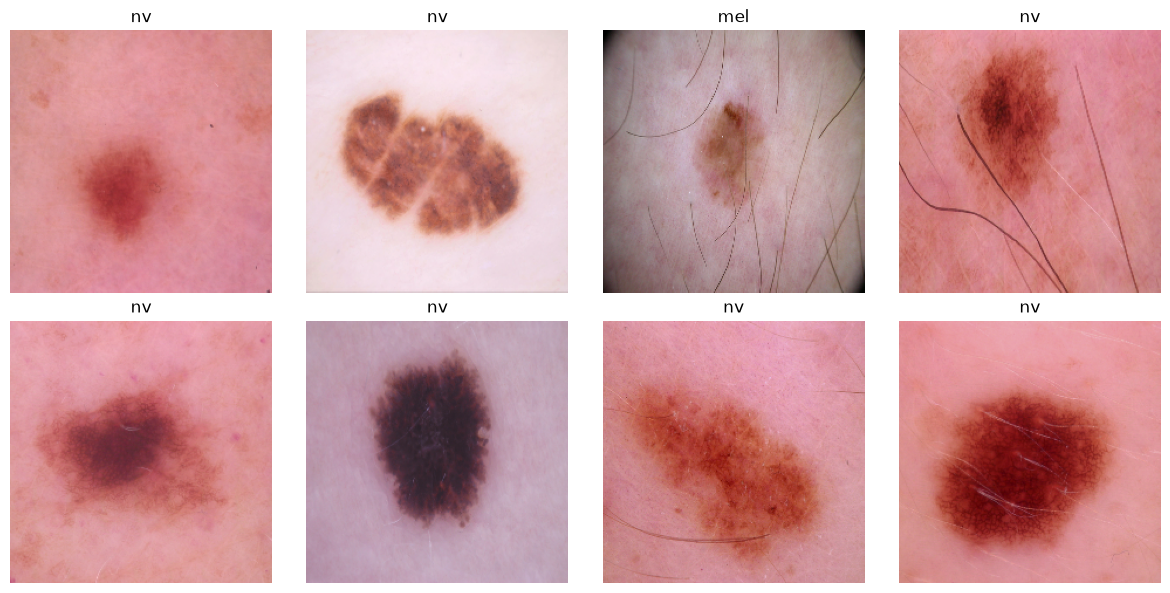

In [1]:
import os, sys
PROJECT_ROOT = os.path.abspath("..")
sys.path.append(PROJECT_ROOT)

import numpy as np
import matplotlib.pyplot as plt
from src.data import load_split, make_dataset, CLASSES

train_df, val_df, test_df = load_split(PROJECT_ROOT)
print("Sizes:", len(train_df), len(val_df), len(test_df))

train_ds = make_dataset(train_df, batch_size=32, training=True)
val_ds = make_dataset(val_df, batch_size=32, training=False)

imgs, labels = next(iter(train_ds))
print("Batch shape:", imgs.shape, "| dtype:", imgs.dtype)
print("Pixel range:", float(imgs.numpy().min()), "to", float(imgs.numpy().max()))
print("Labels in batch:", labels.numpy()[:12], "->", [CLASSES[i] for i in labels.numpy()[:12]])

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, lab in zip(axes.ravel(), imgs[:8], labels[:8]):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title(CLASSES[int(lab)])
    ax.axis("off")
plt.tight_layout()
plt.show()